<a href="https://colab.research.google.com/github/sohyun223/ai-application-2026/blob/main/Week04_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4주차 실습 — 내 데이터셋 v0 만들기 (파이프라인 ① 수집)
**AI Application · 스마트모빌리티학과 · 2026-09-23**

오늘부터 스타터 킷 **`tinytrack.py`** 를 씁니다. 3주차 렌더러에 트랙·차량 운동학·데이터 수집·폐루프 평가·ONNX 정책이 더해진 파일 하나입니다.

| 단계 | 이 노트북에서 |
|---|---|
| 1 | 트랙 A/B/C/랜덤 — 중심선과 곡률 프로파일 |
| 2 | 전문가로 환경 굴려보기 |
| 3 | 깨끗한 전문가 데이터 수집 → 라벨 분포·상태 커버리지 |
| 4 | 노이즈 주입(복구 데이터) 수집 → 커버리지 비교 |
| 5 | 트랙 3개 × 3수준 → 병합 → **my_dataset_v0.npz** + 데이터 카드 |
| 6 | 주행 단위 분할 확인 |
| 7 | 전문가 폐루프 점수 — 리더보드 상한 |

**준비물**: 배포 저장소 `e2e_starter/tinytrack.py` (0번 셀에서 업로드 창이 뜹니다)

**약어**: E2E = End-to-End(이미지 → 조향을 한 네트워크로) · npz = numpy 압축 배열 파일(.npz) · run = 한 번의 연속 주행(시작 → 이탈/종료) · MAE = 평균절대오차 · DART = Disturbances for Augmenting Robot Trajectories(노이즈 주입 수집법, Laskey 외 CoRL 2017) · ONNX = Open Neural Network Exchange(프레임워크 공통 모델 형식) · PilotNet = NVIDIA 의 E2E 조향 CNN(Bojarski 외 2016, arXiv:1604.07316)
**Colab 생존 규칙**: 결과는 Drive `AIApp/week04` 에 저장. 끊기면 0번 셀부터. CPU 런타임으로 충분 (전체 10분 안팎).

In [ ]:
# ============ 0. 패키지 + tinytrack + Drive (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json
for pkg in ["onnx", "onnxruntime"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

try:
    import tinytrack as tt
except ImportError:
    try:
        from google.colab import files
        print("tinytrack.py 를 업로드하세요 (배포 저장소 e2e_starter/tinytrack.py)")
        files.upload()
        import tinytrack as tt
    except ImportError:
        raise SystemExit("tinytrack.py 를 이 노트북과 같은 폴더에 두고 다시 실행하세요")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = Path("/content/drive/MyDrive/AIApp/week04")
except Exception:
    SAVE_DIR = Path("./outputs/week04")
SAVE_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
print("tinytrack", tt.__version__, "| 저장 폴더:", SAVE_DIR)

tinytrack.py 를 업로드하세요 (배포 저장소 e2e_starter/tinytrack.py)


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
tinytrack 0.3.1 | 저장 폴더: /content/drive/MyDrive/AIApp/week04


## 1. 트랙 — 곡률 프로파일이 곧 트랙
`Track` 은 (길이 m, 곡률 1/m) 구간의 반복입니다. 곡률 + 는 좌회전, − 는 우회전.
**A 는 좌회전만 있습니다** — A 만으로 배운 모델은 우회전을 본 적이 없습니다.

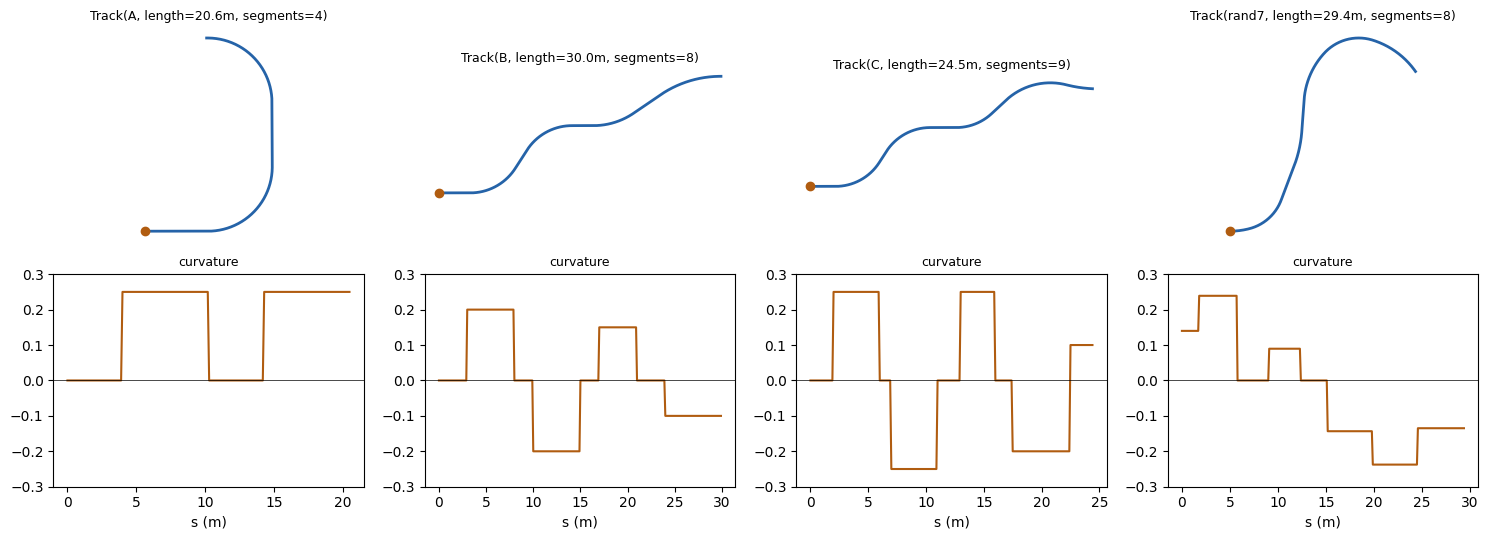

A      길이  20.6 m | 좌회전 61% 직선 39% 우회전 0%
B      길이  30.0 m | 좌회전 30% 직선 33% 우회전 37%
C      길이  24.5 m | 좌회전 37% 직선 27% 우회전 37%
rand7  길이  29.4 m | 좌회전 31% 직선 21% 우회전 48%


In [ ]:
tracks = {n: tt.Track.preset(n) for n in "ABC"}
tracks["rand7"] = tt.Track.random(7)

fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for j, (name, tr) in enumerate(tracks.items()):
    tt.plot_track(tr, ax=axes[0, j])
    ss, ks = tr.profile()
    axes[1, j].plot(ss, ks, color="#B05C10"); axes[1, j].axhline(0, color="k", lw=0.5)
    axes[1, j].set_ylim(-0.3, 0.3); axes[1, j].set_xlabel("s (m)"); axes[1, j].set_title("curvature", fontsize=9)
plt.tight_layout(); plt.show()
for name, tr in tracks.items():
    ss, ks = tr.profile()
    print(f"{name:6s} 길이 {tr.length:5.1f} m | 좌회전 {np.mean(ks>0):.0%} 직선 {np.mean(ks==0):.0%} 우회전 {np.mean(ks<0):.0%}")

## 2. 전문가로 환경 굴려보기
`Env.step(steer)` 한 번 = 0.1초. 전문가는 상태 `(d, psi, kappa)` 를 정확히 알고 조향합니다. 학습된 정책은 **이미지만** 봅니다.

/content/tinytrack.py:453: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 47928 (\N{HANGUL SYLLABLE MUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 53597 (\N{HANGUL SYLLABLE TEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 44036 (\N{HANGUL SYLLA

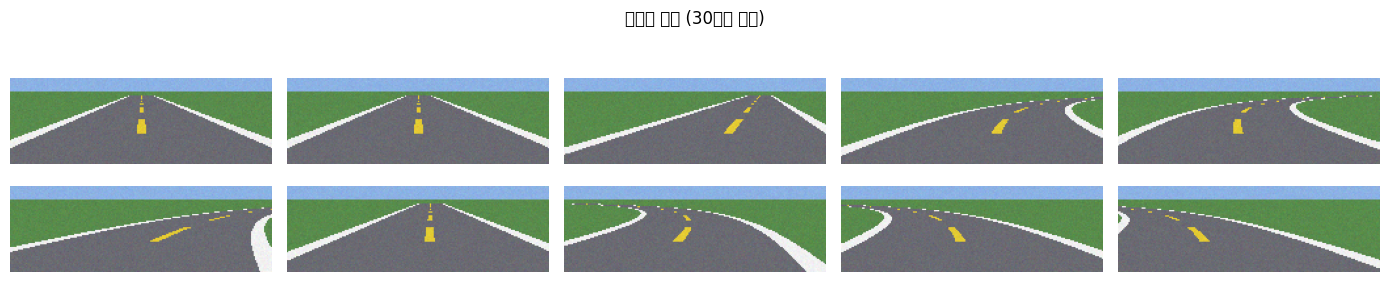

/tmp/ipykernel_2516/656931840.py:18: UserWarning: Glyph 50808 (\N{HANGUL SYLLABLE OE}) missing from font(s) DejaVu Sans.
  ax[2].set_xlabel("step (0.1 s)"); plt.suptitle("외란(50스텝마다)이 들어와도 전문가는 몇 스텝 만에 복귀"); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/656931840.py:18: UserWarning: Glyph 46976 (\N{HANGUL SYLLABLE RAN}) missing from font(s) DejaVu Sans.
  ax[2].set_xlabel("step (0.1 s)"); plt.suptitle("외란(50스텝마다)이 들어와도 전문가는 몇 스텝 만에 복귀"); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/656931840.py:18: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  ax[2].set_xlabel("step (0.1 s)"); plt.suptitle("외란(50스텝마다)이 들어와도 전문가는 몇 스텝 만에 복귀"); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/656931840.py:18: UserWarning: Glyph 53597 (\N{HANGUL SYLLABLE TEB}) missing from font(s) DejaVu Sans.
  ax[2].set_xlabel("step (0.1 s)"); plt.suptitle("외란(50스텝마다)이 들어와도 전문가는 몇 스텝 만에 복귀"); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/656931840.py:18: UserWarn

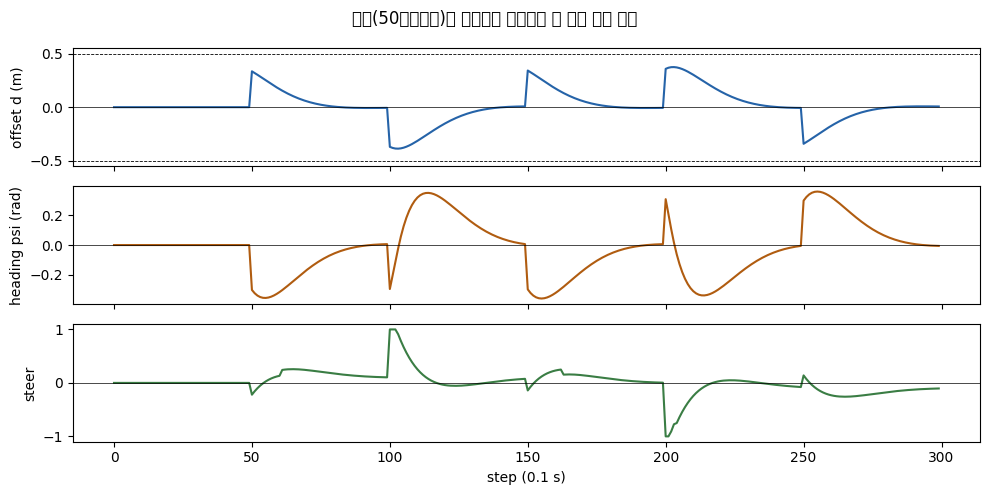

In [ ]:
env = tt.Env(track=tracks["B"], noise=0.02, disturb=tt.DEFAULT_DISTURB, seed=0)
obs = env.reset(seed=0)
frames, log = [], []
for t in range(300):
    d, psi, kappa, s = env.state
    steer = tt.expert_steer(d, psi, kappa)
    log.append((d, psi, kappa, steer))
    if t % 30 == 0: frames.append(obs)
    obs, r, term, trunc, info = env.step(steer)
    if term: print("이탈!", t); break
log = np.array(log)

tt.show_frames(np.array(frames), n=len(frames), title="전문가 주행 (30스텝 간격)"); plt.show()
fig, ax = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for i, (name, c) in enumerate([("offset d (m)", "#2563A8"), ("heading psi (rad)", "#B05C10"), ("steer", "#3A7D44")]):
    ax[i].plot(log[:, [0, 1, 3][i]], color=c); ax[i].set_ylabel(name); ax[i].axhline(0, color="k", lw=0.5)
ax[0].axhline(0.5, ls="--", color="k", lw=0.6); ax[0].axhline(-0.5, ls="--", color="k", lw=0.6)
ax[2].set_xlabel("step (0.1 s)"); plt.suptitle("외란(50스텝마다)이 들어와도 전문가는 몇 스텝 만에 복귀"); plt.tight_layout(); plt.show()

## 3. 깨끗한 전문가 데이터 — 무엇이 빠져 있나
`collect(policy, track, n_steps)` 는 (이미지, 전문가 조향, 상태)를 기록합니다. 저장 이미지는 노이즈 없이(압축 50배), 노이즈는 학습 때 증강으로 넣습니다.

수집 1500장, 5.3초 | {'n': 1500, 'runs': 1, 'straight_frac': 0.6346666666666667, 'abs_d_max': 0.05214608460664749, 'abs_d_mean': 0.0007418918539769948, 'edge_frac': 0.0}


/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48296 (\N{HANGUL SYLLABLE BEL}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu

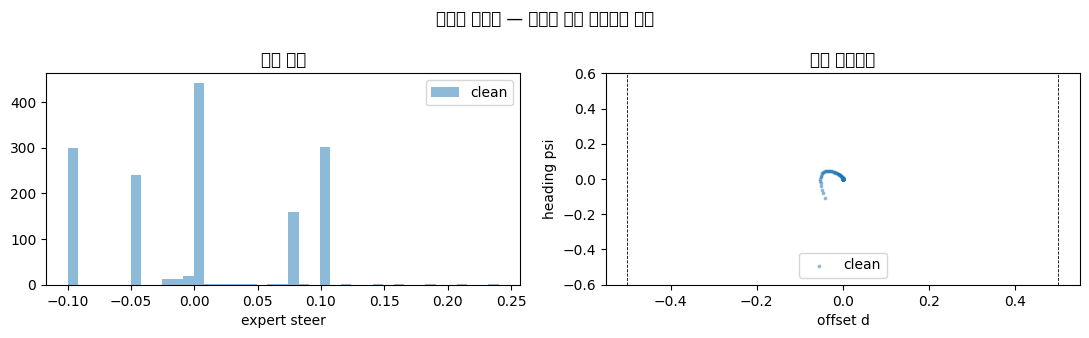

In [ ]:
expert = tt.ExpertPolicy()
t0 = time.time()
clean = tt.collect(expert, tracks["B"], n_steps=1500, seed=1)
print(f"수집 {len(clean['steers'])}장, {time.time()-t0:.1f}초 |", tt.summarize(clean))

def coverage_plot(ds_dict, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for name, ds in ds_dict.items():
        axes[0].hist(ds["steers"], bins=41, alpha=0.5, label=name)
        axes[1].scatter(ds["states"][:, 0], ds["states"][:, 1], s=3, alpha=0.4, label=name)
    axes[0].set_xlabel("expert steer"); axes[0].set_title("라벨 분포"); axes[0].legend()
    axes[1].set_xlim(-0.55, 0.55); axes[1].set_ylim(-0.6, 0.6)
    axes[1].axvline(0.5, ls="--", color="k", lw=0.6); axes[1].axvline(-0.5, ls="--", color="k", lw=0.6)
    axes[1].set_xlabel("offset d"); axes[1].set_ylabel("heading psi"); axes[1].set_title("상태 커버리지"); axes[1].legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()

coverage_plot({"clean": clean}, "깨끗한 전문가 — 상태가 원점 근처에만 있다")

## 4. 복구 데이터 — 노이즈 주입 (DART)
실행하는 조향에 노이즈를 더해 차를 일부러 흔들되, **라벨은 깨끗한 전문가 조향**을 씁니다. 차는 가장자리로 밀려나고, 라벨은 "거기서 돌아오는 정답"이 됩니다.

clean      runs= 1  |d|max=0.05  가장자리(|d|>0.3) 비율=0.0%  직진 비율=63.5%
noise 0.3  runs= 1  |d|max=0.20  가장자리(|d|>0.3) 비율=0.0%  직진 비율=30.8%
noise 0.6  runs= 4  |d|max=0.49  가장자리(|d|>0.3) 비율=3.3%  직진 비율=14.1%


/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48296 (\N{HANGUL SYLLABLE BEL}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu

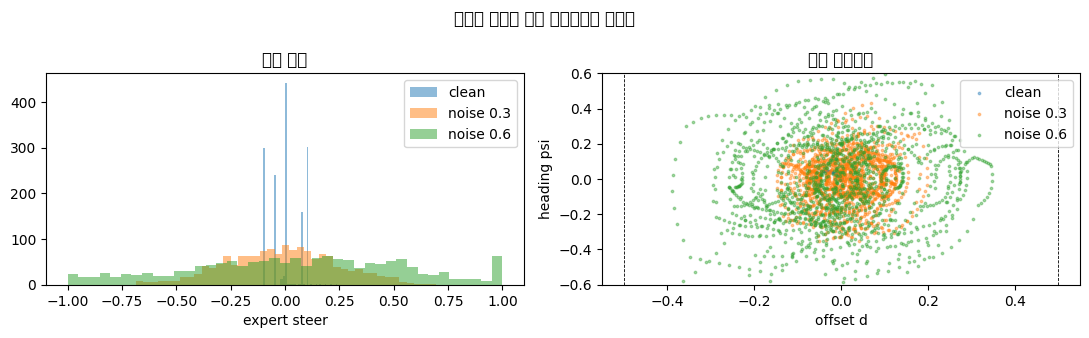

/content/tinytrack.py:453: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 47112 (\N{HANGUL SYLLABLE RE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE S

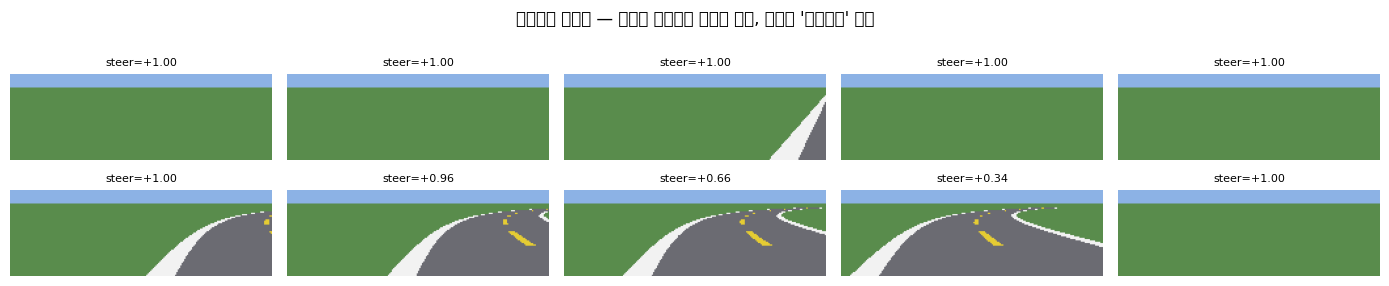

In [ ]:
recov3 = tt.collect(expert, tracks["B"], n_steps=1500, seed=2, noise_inject=0.3)
recov6 = tt.collect(expert, tracks["B"], n_steps=1500, seed=3, noise_inject=0.6)
for name, ds in [("clean", clean), ("noise 0.3", recov3), ("noise 0.6", recov6)]:
    s = tt.summarize(ds)
    print(f"{name:10s} runs={s['runs']:2d}  |d|max={s['abs_d_max']:.2f}  가장자리(|d|>0.3) 비율={s['edge_frac']:.1%}  직진 비율={s['straight_frac']:.1%}")
coverage_plot({"clean": clean, "noise 0.3": recov3, "noise 0.6": recov6}, "노이즈 주입이 상태 커버리지를 넓힌다")

edge = np.where(np.abs(recov6["states"][:, 0]) > 0.35)[0]
tt.show_frames(recov6["images"], recov6["steers"], n=10, idx=edge[:: max(1, len(edge)//10)][:10],
               title="가장자리 프레임 — 차선이 한쪽으로 치우쳐 있고, 라벨은 '돌아오는' 조향"); plt.show()

## 5. 트랙 3개 × 3수준 → my_dataset_v0.npz + 데이터 카드
A 는 좌회전만, B 는 S자, C 는 급커브. 셋을 섞어야 좌·우·급커브를 고루 봅니다.

  track A noise 0.0: runs=1
  track A noise 0.3: runs=1
  track A noise 0.6: runs=2
  track B noise 0.0: runs=1
  track B noise 0.3: runs=1
  track B noise 0.6: runs=1
  track C noise 0.0: runs=1
  track C noise 0.3: runs=1
  track C noise 0.6: runs=1

병합: {'n': 4500, 'runs': 10, 'straight_frac': 0.30622222222222223, 'abs_d_max': 0.499332457780838, 'abs_d_mean': 0.05897707864642143, 'edge_frac': 0.013333333333333334}  (4s)
저장: /content/drive/MyDrive/AIApp/week04/my_dataset_v0.npz  (1.7 MB) + 데이터 카드 JSON
다시 읽기 OK: (4500, 66, 200, 3) | meta: {'name': 'my_dataset_v0', 'author': '학번_이름', 'created': '2026-10-07'}


/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48296 (\N{HANGUL SYLLABLE BEL}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.suptitle(title); plt.tight_layout(); plt.show()
/tmp/ipykernel_2516/2251969728.py:15: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu S

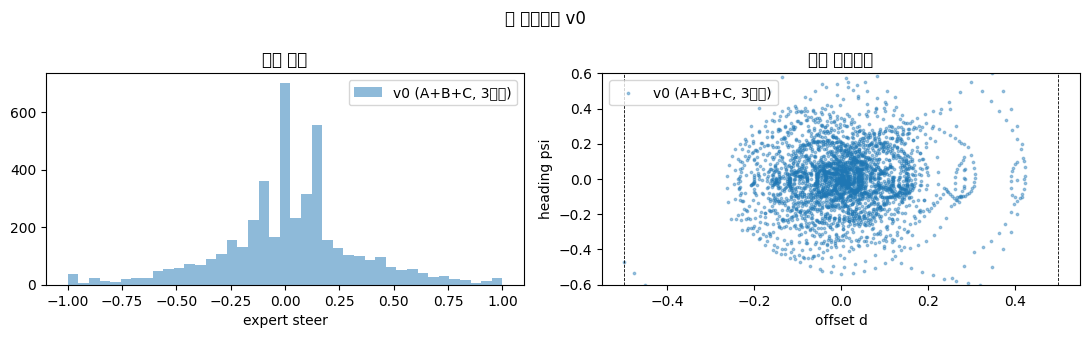

In [ ]:
parts, card_parts = [], []
t0 = time.time()
for name in "ABC":
    for k, ni in enumerate([0.0, 0.3, 0.6]):
        ds = tt.collect(expert, tracks[name], n_steps=500, seed=10 * ord(name) + k, noise_inject=ni)
        parts.append(ds); card_parts.append(dict(track=name, noise_inject=ni, frames=int(len(ds["steers"]))))
        print(f"  track {name} noise {ni}: runs={tt.summarize(ds)['runs']}")
v0 = tt.merge(*parts)
print(f"\n병합: {tt.summarize(v0)}  ({time.time()-t0:.0f}s)")

AUTHOR = "학번_이름"          # ← 본인 것으로 바꾸세요
card = dict(name="my_dataset_v0", author=AUTHOR, created=time.strftime("%Y-%m-%d"),
            tinytrack=tt.__version__, expert="ExpertPolicy(kd=2.0,kpsi=1.5)", parts=card_parts,
            summary=tt.summarize(v0))
size = tt.save_npz(SAVE_DIR / "my_dataset_v0.npz", v0, **{k: v for k, v in card.items() if k != "summary"})
with open(SAVE_DIR / "my_dataset_v0.json", "w", encoding="utf-8") as f:
    json.dump(card, f, ensure_ascii=False, indent=1)
print(f"저장: {SAVE_DIR/'my_dataset_v0.npz'}  ({size/1e6:.1f} MB) + 데이터 카드 JSON")

ds_back = tt.load_npz(SAVE_DIR / "my_dataset_v0.npz")
print("다시 읽기 OK:", ds_back["images"].shape, "| meta:", {k: ds_back["meta"][k] for k in ("name", "author", "created")})
coverage_plot({"v0 (A+B+C, 3수준)": v0}, "내 데이터셋 v0")

## 6. 주행 단위 분할 — 누수 없는 검증
프레임을 섞어 나누면 인접 프레임이 학습·검증 양쪽에 들어가 검증 점수가 부풀려집니다. `split_by_run` 은 run 단위로 뗍니다.

In [ ]:
tr, va = tt.split_by_run(v0, val_frac=0.2, seed=0)
print(f"학습 {len(tr['steers'])}장 ({len(np.unique(tr['run_id']))} runs) / 검증 {len(va['steers'])}장 ({len(np.unique(va['run_id']))} runs)")
assert not set(np.unique(tr["run_id"])) & set(np.unique(va["run_id"])), "run 이 겹치면 누수!"
print("학습·검증 run 겹침 없음 ✓")

학습 3743장 (8 runs) / 검증 757장 (2 runs)
학습·검증 run 겹침 없음 ✓


## 7. 전문가 폐루프 점수 — 리더보드의 상한
`evaluate()` 가 챌린지 평가 하네스와 같은 함수입니다. 외란(50스텝마다)을 포함하므로 전문가도 100점이 아닙니다.

In [ ]:
t0 = time.time()
res = tt.evaluate(expert, tracks=["A", "B", "C", tt.Track.random(101)], max_steps=1500, verbose=True)
print(f"\n전문가: completion={res['completion']:.2f}  offtrack={res['offtrack_rate']:.2f}  mean|d|={res['mean_abs_d']:.3f}  score={res['score']:.1f}   ({time.time()-t0:.0f}s)")
with open(SAVE_DIR / "leaderboard_expert.json", "w") as f:
    json.dump(res, f, indent=1)
print("score 공식: 100 × completion × (1 − 0.5·offtrack) × (1 − 0.5·mean|d|/0.5)")

  A: completion=1.00 off=0.00 |d|=0.102
  B: completion=1.00 off=0.00 |d|=0.102
  C: completion=1.00 off=0.00 |d|=0.102
  rand101: completion=1.00 off=0.00 |d|=0.102

전문가: completion=1.00  offtrack=0.00  mean|d|=0.102  score=89.8   (14s)
score 공식: 100 × completion × (1 − 0.5·offtrack) × (1 − 0.5·mean|d|/0.5)


## 정리
- 트랙은 곡률 프로파일. **A 만으로는 우회전을 못 배운다** — 다양성이 양보다 중요.
- 깨끗한 전문가 데이터는 원점 근처 상태만 담는다. **노이즈 주입**이 복구 데이터를 만든다.
- `my_dataset_v0.npz` + 데이터 카드가 Drive 에 저장됐는지 확인하세요 — **다음 주 과제 2 의 입력**입니다.
- 전문가 score ≈ 90 이 상한. 6주차 첫 모델은 40~70 에서 시작할 겁니다.

**다음 주(9/30, 녹화)**: 행동 복제 이론 + 과제 2(데이터 정제: 리밸런스·증강·분할 → v1). 마감 10/6(화) 23:59.